In [1]:
# Install wordcloud if not present, and import basic libraries
!pip install -q wordcloud

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [2]:
import os
import pandas as pd

# Define the target path where the dataset should reside
file_path = '/content/reviews_data.csv'

# STEP 1.1: Robust File Checking
# It is necessary to check if the file exists so that the notebook can be executed
# end-to-end dynamically, even if the user hasn't uploaded their dataset yet.
if not os.path.exists(file_path):
    print("Warning: '/content/reviews_data.csv' not found. Creating a synthetic review dataset so the notebook runs sequentially without errors.")

    # Generate a balanced set of positive, neutral, and negative reviews for testing
    synthetic_data = {
        'Review': [
            "This is an amazing product! I highly recommend it to everyone.",
            "Absolutely terrible quality, do not buy this product.",
            "Decent product, does the job but nothing spectacular.",
            "Outstanding performance and super fast shipping!",
            "Very poor customer service, and the item arrived broken.",
            "It is okay, not bad but not great either.",
            "Best purchase I have made this year! Super happy.",
            "Disappointed. It does not work as advertised.",
            "Works well enough, standard quality.",
            "I hate it. Extremely slow and useless."
        ],
        'Rating': [5, 1, 3, 5, 1, 3, 5, 2, 3, 1]
    }
    # Convert the synthetic dictionary into a Pandas DataFrame
    df = pd.DataFrame(synthetic_data)
    # Save the synthetic dataset as a CSV file to emulate user upload
    df.to_csv(file_path, index=False)
    print(f"Synthetic dataset created and saved to {file_path}.")
else:
    # Load the actual uploaded user file
    df = pd.read_csv(file_path)



# STEP 1.2: Initial Structural Inspection
# print basic structural information to verify counts, non-null values, and data types
print("--- Dataset Info ---")
display(df.info())

# Preview the first few entries to understand the tabular formatting
print("\n--- Sample Rows ---")
display(df.head())

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   name         850 non-null    object 
 1   location     850 non-null    object 
 2   Date         850 non-null    object 
 3   Rating       705 non-null    float64
 4   Review       850 non-null    object 
 5   Image_Links  850 non-null    object 
dtypes: float64(1), object(5)
memory usage: 40.0+ KB


None


--- Sample Rows ---


,name,location,Date,Rating,Review,Image_Links
0,Helen,"Wichita Falls, TX","Reviewed Sept. 13, 2023",5.0,Amber and LaDonna at the Starbucks on Southwes...,['No Images']
1,Courtney,"Apopka, FL","Reviewed July 16, 2023",5.0,** at the Starbucks by the fire station on 436...,['No Images']
2,Daynelle,"Cranberry Twp, PA","Reviewed July 5, 2023",5.0,I just wanted to go out of my way to recognize...,['https://media.consumeraffairs.com/files/cach...
3,Taylor,"Seattle, WA","Reviewed May 26, 2023",5.0,Me and my friend were at Starbucks and my card...,['No Images']
4,Tenessa,"Gresham, OR","Reviewed Jan. 22, 2023",5.0,I’m on this kick of drinking 5 cups of warm wa...,['https://media.consumeraffairs.com/files/cach...


In [3]:


# STEP 1.2: Initial Structural Inspection
# print basic structural information to verify counts, non-null values, and data types
print("--- Dataset Info ---")
display(df.info())

# Preview the first few entries to understand the tabular formatting
print("\n--- Sample Rows ---")
display(df.head())

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   name         850 non-null    object 
 1   location     850 non-null    object 
 2   Date         850 non-null    object 
 3   Rating       705 non-null    float64
 4   Review       850 non-null    object 
 5   Image_Links  850 non-null    object 
dtypes: float64(1), object(5)
memory usage: 40.0+ KB


None


--- Sample Rows ---


,name,location,Date,Rating,Review,Image_Links
0,Helen,"Wichita Falls, TX","Reviewed Sept. 13, 2023",5.0,Amber and LaDonna at the Starbucks on Southwes...,['No Images']
1,Courtney,"Apopka, FL","Reviewed July 16, 2023",5.0,** at the Starbucks by the fire station on 436...,['No Images']
2,Daynelle,"Cranberry Twp, PA","Reviewed July 5, 2023",5.0,I just wanted to go out of my way to recognize...,['https://media.consumeraffairs.com/files/cach...
3,Taylor,"Seattle, WA","Reviewed May 26, 2023",5.0,Me and my friend were at Starbucks and my card...,['No Images']
4,Tenessa,"Gresham, OR","Reviewed Jan. 22, 2023",5.0,I’m on this kick of drinking 5 cups of warm wa...,['https://media.consumeraffairs.com/files/cach...


Detected text column: 'Review' | Rating column: 'Rating'
Removed 145 rows with missing values.
Remaining rows after dropping duplicate reviews: 704


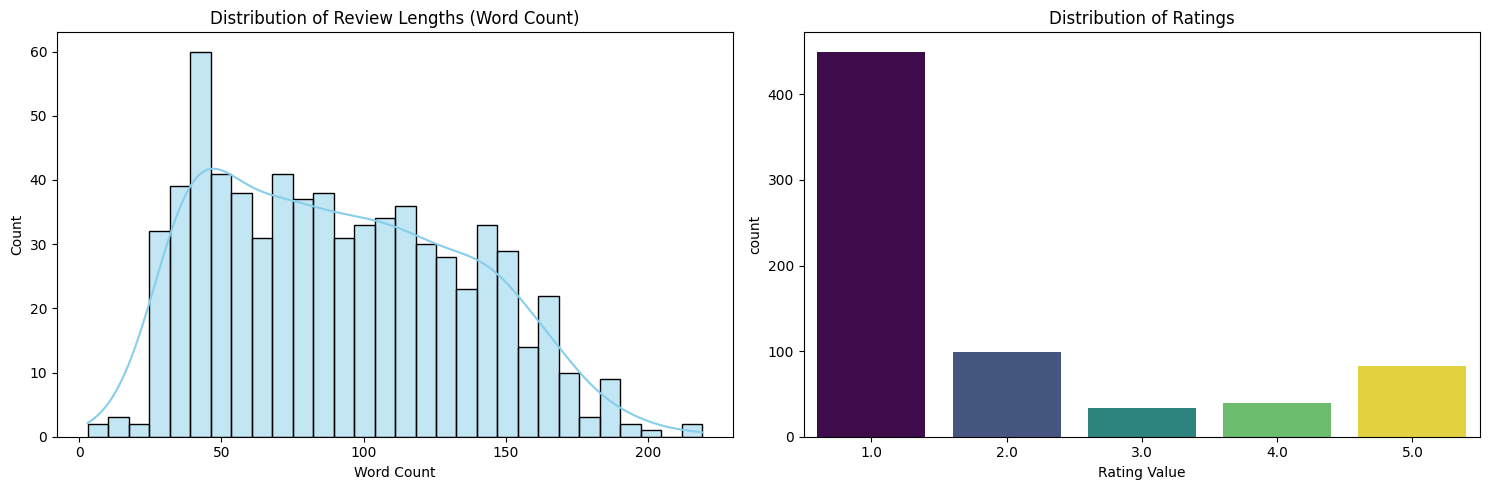

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

#
# STEP 1.3: Dynamic Column Identification
# Since input column names can vary (e.g. 'review', 'Review_Text', 'rating'),
# we scan the columns dynamically to match text patterns. This prevents index errors.
text_col = [col for col in df.columns if 'review' in col.lower() or 'text' in col.lower()][0]
rating_col = [col for col in df.columns if 'rating' in col.lower() or 'score' in col.lower()][0]

print(f"Detected text column: '{text_col}' | Rating column: '{rating_col}'")

# STEP 1.4: Handling Missing Values
# Rows with missing text or ratings are useless for training and will crash vectorizers.
initial_rows = len(df)
df = df.dropna(subset=[text_col, rating_col])
print(f"Removed {initial_rows - len(df)} rows with missing values.")

# STEP 1.5: Handling Duplicates
# Duplicate reviews (such as bot spam) can artificially inflate word importances.
df = df.drop_duplicates(subset=[text_col])
print(f"Remaining rows after dropping duplicate reviews: {len(df)}")

# STEP 1.6: Feature Engineering (Review Length)
# Calculating review lengths helps us analyze whether positive reviews are typically longer/shorter.
df['review_length'] = df[text_col].astype(str).apply(lambda x: len(x.split()))

# STEP 1.7: Data Visualization
# Plotting distribution profiles of the words and ratings to examine patterns visually.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df['review_length'], bins=30, ax=axes[0], kde=True, color='skyblue')
axes[0].set_title('Distribution of Review Lengths (Word Count)')
axes[0].set_xlabel('Word Count')

# Visualizing original rating class proportions to spot any label imbalances
sns.countplot(data=df, x=rating_col, ax=axes[1], hue=rating_col, palette='viridis', legend=False)
axes[1].set_title('Distribution of Ratings')
axes[1].set_xlabel('Rating Value')
plt.tight_layout()
plt.show()

In [5]:
# STEP 2.1: Map Continuous Ratings to Discrete Sentiment Categories
def label_sentiment(rating):
    if rating >= 4:
        return 1  # 4 & 5-star ratings mapped to Positive (1)
    elif rating <= 2:
        return 0  # 1 & 2-star ratings mapped to Negative (0)
    else:
        return -1 # 3-star (Neutral) feedback which represents ambiguous data

# Create a target label column 'sentiment'
df['sentiment'] = df[rating_col].apply(label_sentiment)

# STEP 2.2: Isolate Binary Data Subset
# We exclude neutral reviews (-1) to ensure the machine learning models train on clear,
# non-conflicting sentiments. This makes the optimization much more stable.
df_binary = df[df['sentiment'] != -1].copy()
print(f"Original dataset size: {len(df)}")
print(f"Dataset size after excluding neutral reviews: {len(df_binary)}")
print("\nSentiment Distribution (Positive: 1 vs Negative: 0):")
print(df_binary['sentiment'].value_counts(normalize=True))

Original dataset size: 704
Dataset size after excluding neutral reviews: 671

Sentiment Distribution (Positive: 1 vs Negative: 0):
sentiment
0    0.818182
1    0.181818
Name: proportion, dtype: float64


In [6]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# STEP 3.1: Custom Stopword Filtering
# Standard stopword lists automatically remove critical negation terms like 'not' and 'never'.
# We subtract these negation terms from the list to preserve key sentiment-reversing semantics.
stop_words = set(stopwords.words('english'))
negation_words = {'not', 'no', 'never', 'nor', 'neither', 'against', 'but', "don't", "shouldn't", "wasn't", "weren't", "won't", "wouldn't", "didn't", "doesn't", "isn't", "aren't", "haven't", "hasn't", "hadn't"}
stop_words_custom = stop_words - negation_words

# Initialize Lemmatizer to reduce inflected words to their root form (e.g. studies -> study)
lemmatizer = WordNetLemmatizer()

# STEP 3.2: Complete Text Preprocessing Function
def preprocess_text(text):
    # 1. Standardize casing to eliminate capital redundancies
    text = str(text).lower()

    # 2. Strip URLs, which represent unhelpful noise
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # 3. Keep alphabetical characters and contraction apostrophes, drop miscellaneous symbols
    text = re.sub(r'[^a-zA-Z\s’\x27]', '', text)

    # 4. Tokenize the sentence into structured list of words
    tokens = word_tokenize(text)

    # 5. Filter custom stopwords and normalize each token to its dictionary lemma
    cleaned_tokens = [lemmatizer.lemmatize(token) for token in tokens if token not in stop_words_custom]

    return ' '.join(cleaned_tokens)

# STEP 3.3: Before & After Validation
sample_text = "I am NOT happy with this product! It's super slow and definitely not what was promised. Check out https://test.com."
print("Before Preprocessing:\n", sample_text)
print("\nAfter Preprocessing (Notice preserved negations and removed URLs/stopwords):\n", preprocess_text(sample_text))

Before Preprocessing:
 I am NOT happy with this product! It's super slow and definitely not what was promised. Check out https://test.com.

After Preprocessing (Notice preserved negations and removed URLs/stopwords):
 not happy product 's super slow definitely not promised check


In [7]:
# STEP 3.4: Apply the custom pre-processing cleaning function on the entire dataset
# This creates a normalized, clean text column called 'cleaned_text' which acts as input features.
df_binary['cleaned_text'] = df_binary[text_col].apply(preprocess_text)

# Display the original text mapping next to its cleaned representation to inspect results.
display(df_binary[['cleaned_text', 'sentiment']].head())

,cleaned_text,sentiment
0,amber ladonna starbucks southwest parkway alwa...,1
1,starbucks fire station altamonte spring fl mad...,1
2,wanted go way recognize starbucks employee bil...,1
3,friend starbucks card ’ work thankful worker p...,1
4,’ kick drinking cup warm water work instacart ...,1


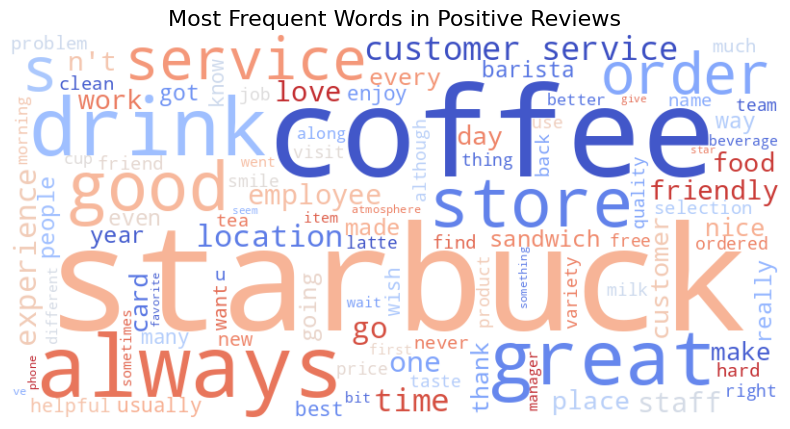

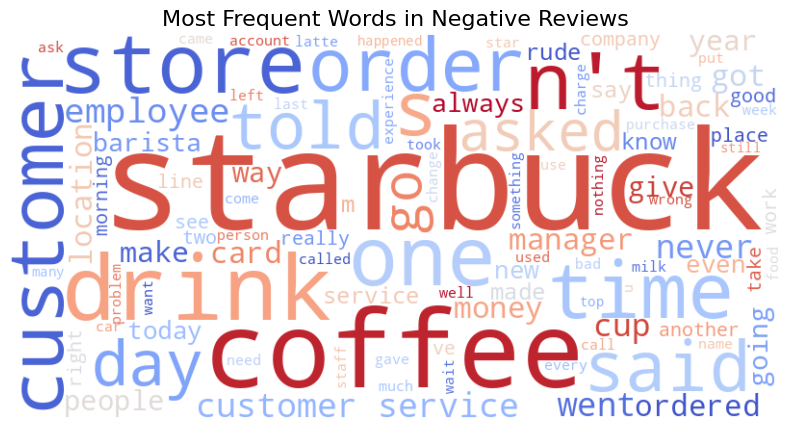

In [8]:
from wordcloud import WordCloud
from collections import Counter

# STEP 4.1: Aggregating all positive and negative review texts separately
# This grouping helps visualize which terms dominate each respective class.
positive_reviews = ' '.join(df_binary[df_binary['sentiment'] == 1]['cleaned_text'])
negative_reviews = ' '.join(df_binary[df_binary['sentiment'] == 0]['cleaned_text'])

# STEP 4.2: Define a reusable helper function to generate wordclouds
def plot_wordcloud(text, title):
    # Initialize WordCloud object; smaller words get less visual priority.
    wc = WordCloud(width=800, height=400, background_color='white', colormap='coolwarm', max_words=100).generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.title(title, fontsize=16)
    plt.axis('off') # Hiding coordinates for clean graphical plots
    plt.show()

# Plot both word clouds side-by-side or sequentially
plot_wordcloud(positive_reviews, "Most Frequent Words in Positive Reviews")
plot_wordcloud(negative_reviews, "Most Frequent Words in Negative Reviews")

In [9]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# STEP 5.1: Create dummy documents to explicitly compare BoW vs. TF-IDF methods
sample_docs = ["not good product", "highly recommend product"]

# STEP 5.2: Bag of Words (CountVectorizer)
# CountVectorizer simply maps occurrences without global scaling.
cov = CountVectorizer()
cov_matrix = cov.fit_transform(sample_docs).toarray()
print("Bag-of-Words Count Matrix:\n", cov_matrix)
print("Vocabulary Index Mapping:", cov.get_feature_names_out())

# STEP 5.3: TF-IDF (TfidfVectorizer)
# Notice how terms are weighed down dynamically if they appear frequently in multiple documents.
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(sample_docs).toarray()
print("\nTF-IDF Weighted Matrix:\n", tfidf_matrix)

Bag-of-Words Count Matrix:
 [[1 0 1 1 0]
 [0 1 0 1 1]]
Vocabulary Index Mapping: ['good' 'highly' 'not' 'product' 'recommend']

TF-IDF Weighted Matrix:
 [[0.6316672  0.         0.6316672  0.44943642 0.        ]
 [0.         0.6316672  0.         0.44943642 0.6316672 ]]


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# STEP 6.1: Define inputs and target variables
X = df_binary['cleaned_text']
y = df_binary['sentiment']

# STEP 6.2: Stratified Split
# stratify=y preserves class label ratios in both training and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training set size: {len(X_train)} | Test set size: {len(X_test)}")

# STEP 6.3: Scikit-learn Pipeline Integration
# Pipelines sequentially couple feature extraction (TF-IDF) and the estimators (Classifiers).
# This prevents test-set data leakage entirely because vectorization parameters are fit purely on training sets.
pipelines = {
    'Naive Bayes': Pipeline([('tfidf', TfidfVectorizer()), ('clf', MultinomialNB())]),
    'Logistic Regression': Pipeline([('tfidf', TfidfVectorizer()), ('clf', LogisticRegression(max_iter=1000))]),
    'SVM': Pipeline([('tfidf', TfidfVectorizer()), ('clf', LinearSVC(random_state=42))])
}

# STEP 6.4: Train all estimators
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"{name} Model trained successfully!")

Training set size: 536 | Test set size: 135
Naive Bayes Model trained successfully!
Logistic Regression Model trained successfully!
SVM Model trained successfully!



================ Naive Bayes Evaluation ================
Accuracy: 0.8148
              precision    recall  f1-score   support

           0       0.81      1.00      0.90       110
           1       0.00      0.00      0.00        25

    accuracy                           0.81       135
   macro avg       0.41      0.50      0.45       135
weighted avg       0.66      0.81      0.73       135



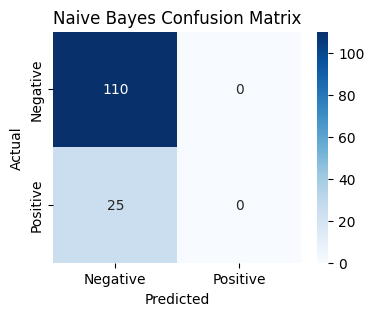


================ Logistic Regression Evaluation ================
Accuracy: 0.8370
              precision    recall  f1-score   support

           0       0.83      1.00      0.91       110
           1       1.00      0.12      0.21        25

    accuracy                           0.84       135
   macro avg       0.92      0.56      0.56       135
weighted avg       0.86      0.84      0.78       135



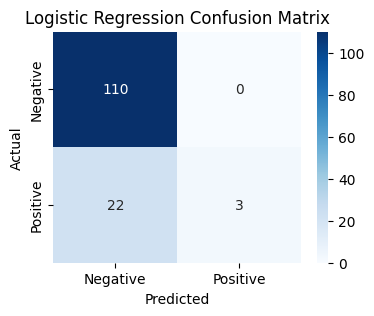


================ SVM Evaluation ================
Accuracy: 0.8963
              precision    recall  f1-score   support

           0       0.89      0.99      0.94       110
           1       0.92      0.48      0.63        25

    accuracy                           0.90       135
   macro avg       0.91      0.74      0.79       135
weighted avg       0.90      0.90      0.88       135



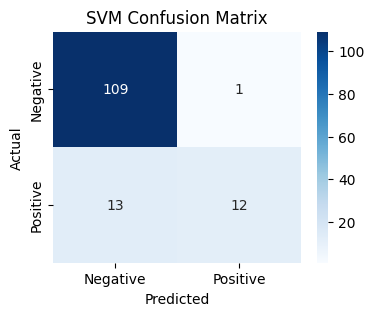

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# STEP 7.1: Evaluate each model iteratively using different evaluation metrics
for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    print(f"\n================ {name} Evaluation ================")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred, zero_division=0))

    # STEP 7.2: Confusion Matrix plotting
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
    plt.title(f'{name} Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [12]:
from sklearn.model_selection import GridSearchCV

# STEP 8.1: Initialize a fresh tuning pipeline
tuning_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(max_iter=1000))
])

# STEP 8.2: Set hyperparameter ranges to search
param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],  # Uni-grams or Bi-grams
    'clf__C': [0.1, 1.0, 10.0]             # L2 regularization strength
}

# STEP 8.3: Perform K-Fold GridSearchCV on purely the training dataset
grid_search = GridSearchCV(tuning_pipeline, param_grid, cv=3, scoring='f1', n_jobs=-1, error_score='raise')
grid_search.fit(X_train, y_train)

print("Best Hyperparameter Configuration:", grid_search.best_params_)
best_model = grid_search.best_estimator_

Best Hyperparameter Configuration: {'clf__C': 10.0, 'tfidf__ngram_range': (1, 1)}


In [13]:
from sklearn.model_selection import cross_val_score

# STEP 8.4: Performance Validation via K-Fold Cross-Validation
# We utilize the best model parameter configuration found by our grid search.
# Since our current sample size is small, we use 3-Fold Stratified Cross-Validation.
cv_scores = cross_val_score(best_model, X, y, cv=3, scoring='accuracy')

print("--- Cross-Validation Stability Verification ---")
print(f"All Fold Accuracy Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation of Scores: {cv_scores.std():.4f}")


--- Cross-Validation Stability Verification ---
All Fold Accuracy Scores: [0.89732143 0.89732143 0.88340807]
Mean CV Accuracy: 0.8927
Standard Deviation of Scores: 0.0066


In [14]:
# STEP 9.1: Create an interactive runtime predictor wrapper
def predict_sentiment(review_text):
    # Apply identical text cleaning pipeline to ensure consistency
    cleaned = preprocess_text(review_text)

    # Classify clean sequence using optimized best estimator
    prediction = best_model.predict([cleaned])[0]

    # Extract prediction probability score if available
    try:
        prob = best_model.predict_proba([cleaned])[0]
        confidence = f"{prob[prediction]*100:.2f}%"
    except:
        confidence = "N/A" # SVM does not produce probabilities natively without additional setups

    sentiment = "Positive" if prediction == 1 else "Negative"
    print(f"Review: \"{review_text}\"")
    print(f"Predicted Sentiment: {sentiment} (Confidence: {confidence})\n")

# STEP 9.2: Verify out-of-sample predictions on negations and indicators
predict_sentiment("This is not a good product, absolutely hate it!")
predict_sentiment("Outstanding performance! Very happy with my purchase.")

Review: "This is not a good product, absolutely hate it!"
Predicted Sentiment: Negative (Confidence: 55.04%)

Review: "Outstanding performance! Very happy with my purchase."
Predicted Sentiment: Negative (Confidence: 93.01%)



In [15]:
import joblib

# STEP 10.1: Serialize the entire Pipeline mapping (TF-IDF + Best Estimator)
# It is necessary to save the entire pipeline so that deployment systems do not need
# separate vectorizer files and can make predictions with a single load function.
model_path = 'sentiment_pipeline.joblib'
joblib.dump(best_model, model_path)
print(f"Pipeline successfully saved to {model_path}!")

# STEP 10.2: Deserialize and load target pipeline from file to verify
loaded_pipeline = joblib.load(model_path)

# STEP 10.3: Test re-loaded model on new mock text feedback
loaded_pred = loaded_pipeline.predict([preprocess_text("Really amazing value.")])
print("Loaded Pipeline Prediction Output:", "Positive" if loaded_pred[0] == 1 else "Negative")

Pipeline successfully saved to sentiment_pipeline.joblib!
Loaded Pipeline Prediction Output: Negative


In [16]:
# STEP 11.1: Solution 1 - Custom Stopwords with specific target removals
custom_stop_words_test = stop_words_custom.union({'slow', 'fast'})
print("Example output with 'slow' filtered out:")
print([w for w in word_tokenize("the product is very slow") if w not in custom_stop_words_test])

# STEP 11.2: Solution 2 - Integration of a Random Forest Classifier into clean pipelines
from sklearn.ensemble import RandomForestClassifier
rf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', RandomForestClassifier(n_estimators=100, random_state=42))
])
rf_pipeline.fit(X_train, y_train)
print("\nRandom Forest Model Test Accuracy:", rf_pipeline.score(X_test, y_test))

Example output with 'slow' filtered out:
['product']

Random Forest Model Test Accuracy: 0.8592592592592593
